In [6]:
import pandas as pd
import numpy as np

In [8]:
df_01 = pd.read_csv("disbursement.csv") 

In [10]:
df = df_01.copy()

In [41]:
def get_dataframe_01(df_01: pd.DataFrame, max_full_dates: int = 40) -> str:
    # 1. Determine if the time axis / identifier is the Index or the First Column
    if isinstance(df_01.index, pd.DatetimeIndex) or df_01.index.name is not None:
        time_series = pd.Series(df_01.index, name=df_01.index.name or "Index")
        source_label = f"DataFrame Index ('{time_series.name}')"
    else:
        time_series = df_01.iloc[:, 0]
        source_label = f"First Column ('{time_series.name}')"

    # 2. Extract sorted unique values from the first column / index
    unique_vals = pd.Series(time_series.dropna().unique()).sort_values().reset_index(drop=True)
    n_unique = len(unique_vals)

    # Calculate time step / granularity if convertible to datetime
    granularity_note = ""
    try:
        dt_vals = pd.to_datetime(unique_vals)
        diffs = dt_vals.diff().dropna()
        if not diffs.empty:
            most_common_step = diffs.mode().iloc[0]
            granularity_note = f" | Modal Time Step: {most_common_step}"
    except Exception:
        pass

    # If unique dates are <= 40 (e.g., monthly/quarterly cohorts), show ALL of them.
    # Otherwise, show the first 5 and last 5 unique dates so we don't blow up num_ctx=8192.
    if n_unique <= max_full_dates:
        date_values_str = f"All {n_unique} unique values: {unique_vals.astype(str).tolist()}"
    else:
        first_5 = unique_vals.head(5).astype(str).tolist()
        last_5 = unique_vals.tail(5).astype(str).tolist()
        date_values_str = (
            f"{n_unique} unique values from {first_5[0]} to {last_5[-1]}\n"
            f"- Earliest 5 unique dates: {first_5}\n"
            f"- Latest 5 unique dates:   {last_5}"
        )

    time_profile = (
        f"### Time / Primary Axis Profile ({source_label}{granularity_note}):\n"
        f"{date_values_str}"
    )

    schema_df = pd.DataFrame({
        "Data Type": df_01.dtypes.astype(str),
        "Missing": df_01.isna().sum(),
        "Unique Count": df_01.nunique(),
        "Min": [df_01[c].dropna().min() if not df_01[c].dropna().empty else None for c in df_01.columns],
        "Max": [df_01[c].dropna().max() if not df_01[c].dropna().empty else None for c in df_01.columns],
    })
    schema_df.index.name = "Column"

    # 4. Show First 5 rows AND Last 5 rows (instead of just head(10))
    head_md = df_01.head(5).to_markdown()
    tail_md = df_01.tail(5).to_markdown()

    return (
        f"### Dataset Shape: {df_01.shape[0]} rows, {df_01.shape[1]} columns\n\n"
        f"{time_profile}\n\n"
        f"### Column Schema:\n{schema_df.to_markdown()}\n\n"
        f"### First 5 Rows (Earliest):\n{head_md}\n\n"
        f"### Last 5 Rows (Latest):\n{tail_md}"
    )

# Generate the context and inspect it
data_context_01 = get_dataframe_01(df_01)
print(data_context_01)

### Dataset Shape: 39 rows, 12 columns

### Time / Primary Axis Profile (First Column ('Month') | Modal Time Step: 365 days 00:00:00):
All 39 unique values: ['1/31/17', '1/31/18', '1/31/19', '10/31/16', '10/31/17', '10/31/18', '11/30/16', '11/30/17', '11/30/18', '12/31/16', '12/31/17', '12/31/18', '2/28/17', '2/28/18', '2/28/19', '2/29/16', '3/31/16', '3/31/17', '3/31/18', '3/31/19', '4/30/16', '4/30/17', '4/30/18', '4/30/19', '5/31/16', '5/31/17', '5/31/18', '6/30/16', '6/30/17', '6/30/18', '7/31/16', '7/31/17', '7/31/18', '8/31/16', '8/31/17', '8/31/18', '9/30/16', '9/30/17', '9/30/18']

### Column Schema:
| Column                               | Data Type   |   Missing |   Unique Count | Min           | Max         |
|:-------------------------------------|:------------|----------:|---------------:|:--------------|:------------|
| Month                                | object      |         0 |             39 | 1/31/17       | 9/30/18     |
| accumulated disbursement amount      | o

/var/folders/8w/mpz_tvmj7b98g9wp3y5d2r3m0000gn/T/ipykernel_20686/1367411510.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dt_vals = pd.to_datetime(unique_vals)


In [43]:


# ==========================================
# STEP 1: Preprocess `df_01` Schema & Types
# ==========================================


# Parse 'Month' as datetime and sort chronologically
df['Month'] = pd.to_datetime(df['Month'])
df = df.set_index('Month').sort_index()

# Clean all 11 numeric columns (strip commas, replace '-' with 0, cast to float)
numeric_cols = [
    'accumulated disbursement amount',
    'accumulated disbursement order count',
    'monthly disbursement amount',
    'monthly orders count',
    'ending balance',
    'overdue 1-7D',
    'overdue 8-30D',
    'overdue 0-30D',
    'overdue 31-60D',
    'overdue 61-90D',
    'overdue 90D+'
]

for col in numeric_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.replace(',', '', regex=False)
        .replace({'-': '0', '': '0', 'nan': '0', 'None': '0'})
        .astype(float)
    )

# Retain the 4 core overdue buckets for transition modeling
bucket_cols = ['overdue 0-30D', 'overdue 31-60D', 'overdue 61-90D', 'overdue 90D+']
df_buckets = df[bucket_cols].copy()

# ==========================================
# STEP 2: Compute Calibrated Roll Rates (%)
# ==========================================
# Forward cohort index: 38 transitions from 2016-02-29 to 2019-03-31
idx = df_buckets.index[:-1]

# Starting balances at month t
b_0_30  = df_buckets['overdue 0-30D'].iloc[:-1]
b_31_60 = df_buckets['overdue 31-60D'].iloc[:-1]
b_61_90 = df_buckets['overdue 61-90D'].iloc[:-1]

# Next month's balances at month t+1
next_31_60 = df_buckets['overdue 31-60D'].shift(-1).iloc[:-1]
next_61_90 = df_buckets['overdue 61-90D'].shift(-1).iloc[:-1]

# Marginal new inflow into cumulative 'overdue 90D+' stock at month t+1
marginal_90_plus = (
    df_buckets['overdue 90D+'].shift(-1).iloc[:-1] - df_buckets['overdue 90D+'].iloc[:-1]
).clip(lower=0.0)

def calibrated_roll_rate(numerator, denominator):
    """
    Compute bounded roll rate in [0.0%, 100.0%]:
    - Avoids X / 0 = inf when starting bucket balance is 0
    - Caps >100% rates (caused by 31-day calendar jumps or penalty interest accrual) at 100.0%
    """
    rate = np.where(denominator > 0, (numerator / denominator) * 100.0, 0.0)
    return pd.Series(np.clip(rate, 0.0, 100.0), index=denominator.index)

roll_rates = pd.DataFrame(index=idx)
roll_rates['0-30D→31-60D']  = calibrated_roll_rate(next_31_60, b_0_30)
roll_rates['31-60D→61-90D'] = calibrated_roll_rate(next_61_90, b_31_60)
roll_rates['61-90D→90D+']   = calibrated_roll_rate(marginal_90_plus, b_61_90)

# ==========================================
# STEP 3: Build Transition Matrix (%)
# ==========================================
# Pairwise complement (100% - Roll Rate); if starting balance is 0, set to 0.0%
transition_matrix = pd.DataFrame(index=idx)
transition_matrix['0-30D→31-60D']  = roll_rates['0-30D→31-60D']
transition_matrix['31-60D→61-90D'] = roll_rates['31-60D→61-90D']
transition_matrix['61-90D→90D+']   = roll_rates['61-90D→90D+']

transition_matrix['0-30D→0-30D']   = np.where(b_0_30 > 0, 100.0 - roll_rates['0-30D→31-60D'], 0.0)
transition_matrix['31-60D→31-60D'] = np.where(b_31_60 > 0, 100.0 - roll_rates['31-60D→61-90D'], 0.0)
transition_matrix['61-90D→61-90D'] = np.where(b_61_90 > 0, 100.0 - roll_rates['61-90D→90D+'], 0.0)

# ==========================================
# STEP 4: 30-Day Cure Cliff Metrics (%)
# ==========================================
cure_cliff = pd.DataFrame(index=idx)
cure_cliff['0-30D→31-60D Roll Rate']  = roll_rates['0-30D→31-60D']
cure_cliff['31-60D→61-90D Roll Rate'] = roll_rates['31-60D→61-90D']

# ==========================================
# STEP 5: Transition Matrix in Currency (RMB)
# ==========================================
# Map each transition column to its respective starting balance at month t
starting_balance_map = {
    '0-30D→31-60D':  b_0_30,
    '31-60D→61-90D': b_31_60,
    '61-90D→90D+':   b_61_90,
    '0-30D→0-30D':   b_0_30,
    '31-60D→31-60D': b_31_60,
    '61-90D→61-90D': b_61_90
}

transition_matrix_dollars = pd.DataFrame(index=idx)
for col, start_bal in starting_balance_map.items():
    transition_matrix_dollars[col] = (transition_matrix[col] / 100.0) * start_bal

# ==========================================
# STEP 6: Output & Export Calibrated Tables
# ==========================================
print("Roll Rates (%):")
print(roll_rates.round(2))

print("\nTransition Matrix (%):")
print(transition_matrix.round(2))

print("\n30-Day Cure Cliff Metrics (%):")
print(cure_cliff.round(2))

print("\nTransition Matrix (RMB):")
print(transition_matrix_dollars.round(2))

# Save calibrated CSVs
roll_rates.round(2).to_csv("roll_rates_final.csv")
transition_matrix.round(2).to_csv("transition_matrix_final.csv")
cure_cliff.round(2).to_csv("cure_cliff_final.csv")
transition_matrix_dollars.round(2).to_csv("transition_matrix_rmb_final.csv")

Roll Rates (%):
            0-30D→31-60D  31-60D→61-90D  61-90D→90D+
Month                                               
2016-02-29          0.00           0.00         0.00
2016-03-31         31.63           0.00         0.00
2016-04-30         20.22          97.81         0.00
2016-05-31         25.05          21.26        95.23
2016-06-30         40.95          47.94       100.00
2016-07-31         10.28          14.74         0.00
2016-08-31          3.45          21.86         0.00
2016-09-30         29.92         100.00        60.60
2016-10-31          3.41           0.00        42.20
2016-11-30         28.54           0.00         0.00
2016-12-31         22.13           0.00         0.00
2017-01-31         13.12          89.76         0.00
2017-02-28         24.55           0.00         0.00
2017-03-31         60.60           0.00         0.00
2017-04-30         10.38          22.73         0.00
2017-05-31         36.17          56.06        27.12
2017-06-30          6.76      

/var/folders/8w/mpz_tvmj7b98g9wp3y5d2r3m0000gn/T/ipykernel_20686/835959421.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Month'] = pd.to_datetime(df['Month'])


In [14]:


# ==========================================
# STEP 1: Preprocess `df_01` Schema & Types
# ==========================================


# Parse 'Month' as datetime and sort chronologically
df['Month'] = pd.to_datetime(df['Month'])
df = df.set_index('Month').sort_index()

# Clean all 11 numeric columns (strip commas, replace '-' with 0, cast to float)
numeric_cols = [
    'accumulated disbursement amount',
    'accumulated disbursement order count',
    'monthly disbursement amount',
    'monthly orders count',
    'ending balance',
    'overdue 1-7D',
    'overdue 8-30D',
    'overdue 0-30D',
    'overdue 31-60D',
    'overdue 61-90D',
    'overdue 90D+'
]

for col in numeric_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.replace(',', '', regex=False)
        .replace({'-': '0', '': '0', 'nan': '0', 'None': '0'})
        .astype(float)
    )

# Retain the 4 core overdue buckets for transition modeling
bucket_cols = ['overdue 0-30D', 'overdue 31-60D', 'overdue 61-90D', 'overdue 90D+']
df_buckets = df[bucket_cols].copy()

# ==========================================
# STEP 2: Compute Calibrated Roll Rates (%)
# ==========================================
# Forward cohort index: 38 transitions from 2016-02-29 to 2019-03-31
idx = df_buckets.index[:-1]

# Starting balances at month t
b_0_30  = df_buckets['overdue 0-30D'].iloc[:-1]  #[:-1] : start from the beginning, and stop just before the last element.
b_31_60 = df_buckets['overdue 31-60D'].iloc[:-1]
b_61_90 = df_buckets['overdue 61-90D'].iloc[:-1]

# Next month's balances at month t+1
next_31_60 = df_buckets['overdue 31-60D'].shift(-1).iloc[:-1]  # .shift(-1) : pulls the next month's data up into the current row
next_61_90 = df_buckets['overdue 61-90D'].shift(-1).iloc[:-1]

# b_0_30 , next_31_60 : a Pandas Series

# Marginal new inflow into cumulative 'overdue 90D+' stock at month t+1
marginal_90_plus = (
    df_buckets['overdue 90D+'].shift(-1).iloc[:-1] - df_buckets['overdue 90D+'].iloc[:-1]
).clip(lower=0.0)

def calibrated_roll_rate(numerator, denominator):
    """
    Compute bounded roll rate in [0.0%, 100.0%]:
    - Avoids X / 0 = inf when starting bucket balance is 0
    - Caps >100% rates (caused by 31-day calendar jumps or penalty interest accrual) at 100.0%
    """
    rate = np.where(denominator > 0, (numerator / denominator) * 100.0, 0.0)
    return pd.Series(np.clip(rate, 0.0, 100.0), index=denominator.index)

roll_rates = pd.DataFrame(index=idx)
roll_rates['0-30D→31-60D']  = calibrated_roll_rate(next_31_60, b_0_30)
roll_rates['31-60D→61-90D'] = calibrated_roll_rate(next_61_90, b_31_60)
roll_rates['61-90D→90D+']   = calibrated_roll_rate(marginal_90_plus, b_61_90)

# ==========================================
# STEP 3: Build Transition Matrix (%)
# ==========================================
# Pairwise complement (100% - Roll Rate); if starting balance is 0, set to 0.0%
transition_matrix = pd.DataFrame(index=idx)
transition_matrix['0-30D→31-60D']  = roll_rates['0-30D→31-60D']
transition_matrix['31-60D→61-90D'] = roll_rates['31-60D→61-90D']
transition_matrix['61-90D→90D+']   = roll_rates['61-90D→90D+']

transition_matrix['0-30D→0-30D']   = np.where(b_0_30 > 0, 100.0 - roll_rates['0-30D→31-60D'], 0.0)
transition_matrix['31-60D→31-60D'] = np.where(b_31_60 > 0, 100.0 - roll_rates['31-60D→61-90D'], 0.0)
transition_matrix['61-90D→61-90D'] = np.where(b_61_90 > 0, 100.0 - roll_rates['61-90D→90D+'], 0.0)

# ==========================================
# STEP 4: 30-Day Cure Cliff Metrics (%)
# ==========================================
cure_cliff = pd.DataFrame(index=idx)
cure_cliff['0-30D→31-60D Roll Rate']  = roll_rates['0-30D→31-60D']
cure_cliff['31-60D→61-90D Roll Rate'] = roll_rates['31-60D→61-90D']

# ==========================================
# STEP 5: Transition Matrix in Currency (RMB)
# ==========================================
# Map each transition column to its respective starting balance at month t
starting_balance_map = {
    '0-30D→31-60D':  b_0_30,
    '31-60D→61-90D': b_31_60,
    '61-90D→90D+':   b_61_90,
    '0-30D→0-30D':   b_0_30,
    '31-60D→31-60D': b_31_60,
    '61-90D→61-90D': b_61_90
}

transition_matrix_dollars = pd.DataFrame(index=idx)
for col, start_bal in starting_balance_map.items():
    transition_matrix_dollars[col] = (transition_matrix[col] / 100.0) * start_bal

# ==========================================
# STEP 6: Output & Export Calibrated Tables
# ==========================================
print("Roll Rates (%):")
print(roll_rates.round(2))

print("\nTransition Matrix (%):")
print(transition_matrix.round(2))

print("\n30-Day Cure Cliff Metrics (%):")
print(cure_cliff.round(2))

print("\nTransition Matrix (RMB):")
print(transition_matrix_dollars.round(2))

# Save calibrated CSVs
roll_rates.round(2).to_csv("roll_rates_final.csv")
transition_matrix.round(2).to_csv("transition_matrix_final.csv")
cure_cliff.round(2).to_csv("cure_cliff_final.csv")
transition_matrix_dollars.round(2).to_csv("transition_matrix_rmb_final.csv")

Roll Rates (%):
            0-30D→31-60D  31-60D→61-90D  61-90D→90D+
Month                                               
2016-02-29          0.00           0.00         0.00
2016-03-31         31.63           0.00         0.00
2016-04-30         20.22          97.81         0.00
2016-05-31         25.05          21.26        95.23
2016-06-30         40.95          47.94       100.00
2016-07-31         10.28          14.74         0.00
2016-08-31          3.45          21.86         0.00
2016-09-30         29.92         100.00        60.60
2016-10-31          3.41           0.00        42.20
2016-11-30         28.54           0.00         0.00
2016-12-31         22.13           0.00         0.00
2017-01-31         13.12          89.76         0.00
2017-02-28         24.55           0.00         0.00
2017-03-31         60.60           0.00         0.00
2017-04-30         10.38          22.73         0.00
2017-05-31         36.17          56.06        27.12
2017-06-30          6.76      

/var/folders/8w/mpz_tvmj7b98g9wp3y5d2r3m0000gn/T/ipykernel_50459/835959421.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Month'] = pd.to_datetime(df['Month'])


In [35]:
print(df.columns.tolist())
print([repr(c) for c in df.columns])   # <- shows spaces / \xa0 / \ufeff

['Month', 'accumulated disbursement amount ', 'accumulated disbursement order count ', 'monthly disbursement amount', 'monthly orders count', 'ending balance', 'overdue 1-7D', 'overdue 8-30D', 'overdue 0-30D', 'overdue 31-60D', 'overdue 61-90D', 'overdue 90D+']
["'Month'", "'accumulated disbursement amount '", "'accumulated disbursement order count '", "'monthly disbursement amount'", "'monthly orders count'", "'ending balance'", "'overdue 1-7D'", "'overdue 8-30D'", "'overdue 0-30D'", "'overdue 31-60D'", "'overdue 61-90D'", "'overdue 90D+'"]


In [16]:
MIN_BAL = 500_000  # RMB

mask = pd.DataFrame({
    '0-30D→31-60D':  b_0_30  > MIN_BAL,
    '31-60D→61-90D': b_31_60 > MIN_BAL,
    '61-90D→90D+':   b_61_90 > MIN_BAL,
})
roll_rates_clean = roll_rates.where(mask)

# Exposure-weighted (pooled) rates over the full period — far more stable than monthly
pooled = pd.Series({
    '0-30D→31-60D':  next_31_60.sum()      / b_0_30.sum()  * 100,
    '31-60D→61-90D': next_61_90.sum()      / b_31_60.sum() * 100,
    '61-90D→90D+':   marginal_90_plus.sum()/ b_61_90.sum() * 100,
}).round(2)
print(pooled)

0-30D→31-60D     14.33
31-60D→61-90D    36.25
61-90D→90D+      47.92
dtype: float64


In [18]:
d1_7  = df['overdue 1-7D'].iloc[:-1].values
d8_30 = df['overdue 8-30D'].iloc[:-1].values
y     = next_31_60.values

coef, *_ = np.linalg.lstsq(np.column_stack([d1_7, d8_30]), y, rcond=None)
early_roll, late_roll = coef

print(f"1-7D  → 31-60D roll: {early_roll:.2%}  →  cure ≈ {1-early_roll:.2%}")
print(f"8-30D → 31-60D roll: {late_roll:.2%}   (partial; remainder spills to 61-90D)")
print(f"Cure cliff ratio: {late_roll/early_roll:.2f}x")

1-7D  → 31-60D roll: 4.58%  →  cure ≈ 95.42%
8-30D → 31-60D roll: 26.98%   (partial; remainder spills to 61-90D)
Cure cliff ratio: 5.89x


In [20]:
d90 = df_buckets['overdue 90D+']
writeoff_mask = d90.diff() < 0          # stock shrank → write-offs or recoveries
print(df.index[writeoff_mask])

DatetimeIndex(['2016-08-31', '2016-09-30', '2016-12-31', '2017-09-30',
               '2017-10-31', '2017-11-30', '2018-01-31', '2018-02-28',
               '2018-03-31', '2018-05-31', '2019-01-31', '2019-02-28'],
              dtype='datetime64[ns]', name='Month', freq=None)


In [22]:
roll_rates['MOY'] = roll_rates.index.month
seasonal = roll_rates.groupby('MOY')[['0-30D→31-60D','31-60D→61-90D']].mean().round(2)

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

# --- inputs you already have ---
# df, df_buckets, roll_rates, transition_matrix, transition_matrix_dollars
# Plus the regression coefficients from your last run:
EARLY_COEF, LATE_COEF = 0.0458, 0.2698   # 1-7D, 8-30D → 31-60D
POOLED = pd.Series({
    '1-7D':      4.58,
    '8-30D':    26.98,
    '0-30D':    14.33,
    '31-60D':   36.25,
    '61-90D':   47.92,
})

# --- identify write-off / thin months to flag ---
d90 = df_buckets['overdue 90D+']
writeoff_months = d90.index[d90.diff() < 0]

# 3-month rolling helper that ignores NaN
def roll3(s, **kw):
    return s.rolling(3, center=True, min_periods=2).mean()

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})

# ---------- palette --------------------------------------------------
P = {
    'navy':        '#0B2545',
    'deep_blue':   '#13315C',
    'steel_blue':  '#1F4E79',
    'blue':        '#2E75B6',
    'sky_blue':    '#5B9BD5',
    'light_blue':  '#9DC3E6',
    'pale_blue':   '#DEEBF7',
    'deep_orange': '#843C0C',
    'dark_orange': '#C55A11',
    'orange':      '#ED7D31',
    'light_orange':'#F4B183',
    'pale_orange': '#FBE5D6',
    'gray':        '#7F7F7F',
}
# stage → colour  (used everywhere below)
STAGE_COLOR = {
    '1-7D':          P['light_blue'],
    '8-30D':         P['sky_blue'],
    '0-30D':         P['steel_blue'],
    '31-60D':        P['orange'],
    '61-90D':        P['dark_orange'],
    '90D+':          P['deep_orange'],
}
ROLL_COLOR = {
    '0-30D→31-60D':  P['steel_blue'],
    '31-60D→61-90D': P['orange'],
    '61-90D→90D+':   P['dark_orange'],
}

# diverging map: low=good=blue  →  50% = white  →  high=bad=orange
blue_orange = LinearSegmentedColormap.from_list('blue_orange', [
    P['navy'], P['steel_blue'], P['sky_blue'],
    '#F7F7F7',
    P['light_orange'], P['orange'], P['deep_orange'],
])

# helpers
def roll3(s): return s.rolling(3, center=True, min_periods=2).mean()
d90 = df_buckets['overdue 90D+']
writeoff_months = d90.index[d90.diff() < 0]

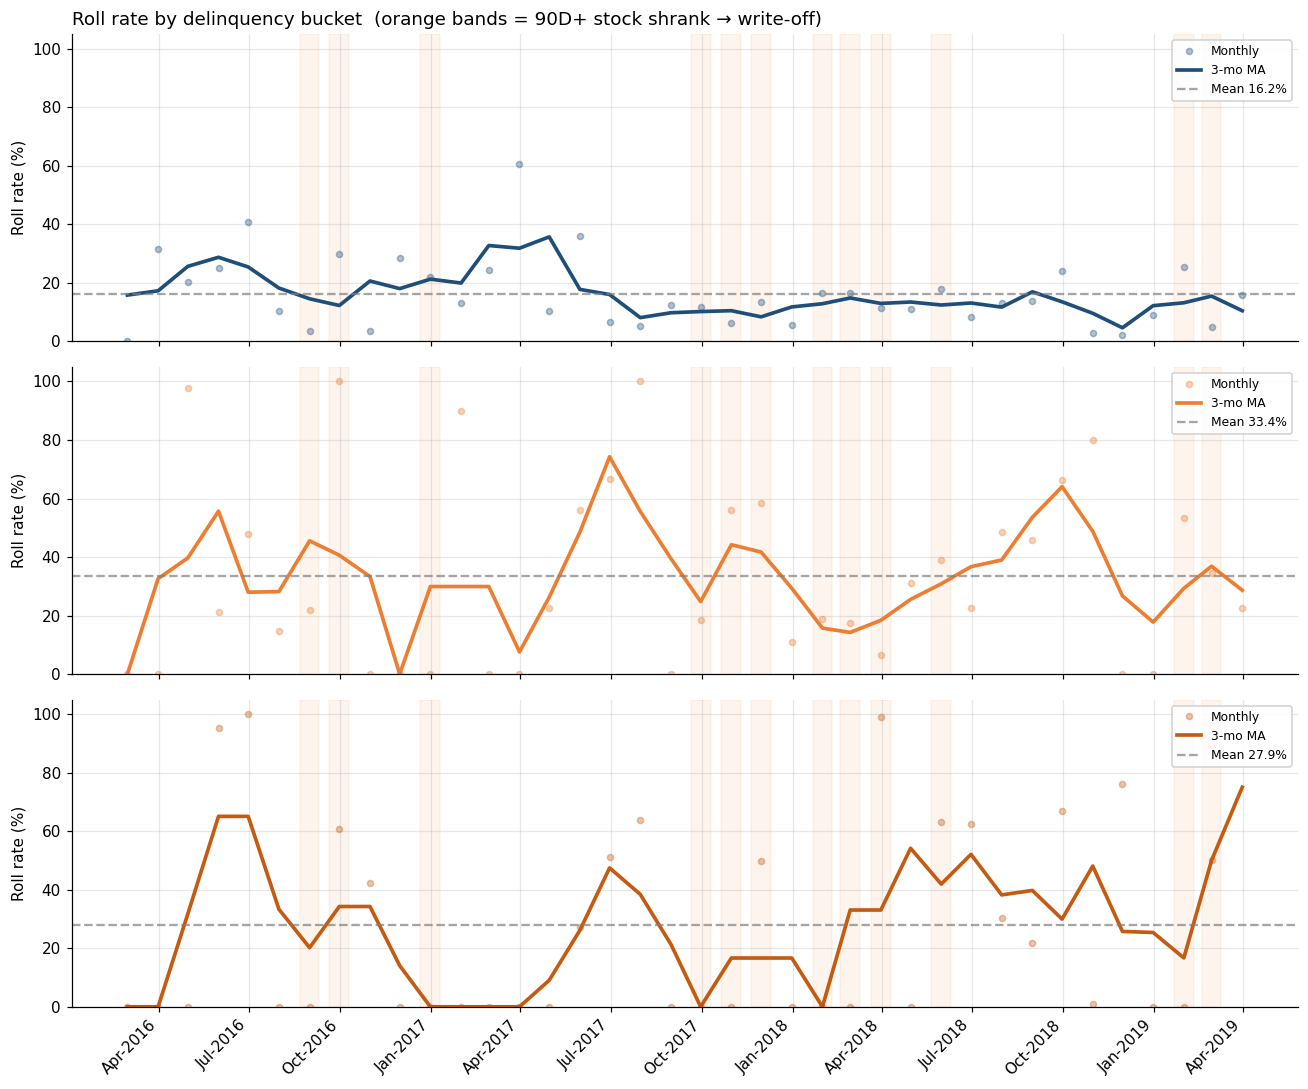

In [44]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, ['0-30D→31-60D', '31-60D→61-90D', '61-90D→90D+']):
    c = ROLL_COLOR[col]
    s = roll_rates[col]
    ax.plot(s.index, s.values, 'o', color=c, alpha=0.35, ms=4, label='Monthly')
    ax.plot(s.index, roll3(s), '-', color=c, lw=2.4, label='3-mo MA')
    ax.axhline(s.mean(), ls='--', color=P['gray'], alpha=0.7,
               label=f'Mean {s.mean():.1f}%')
    ax.set_ylabel('Roll rate (%)'); ax.set_ylim(0, 105)
    ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
    for wm in writeoff_months:
        ax.axvspan(wm - pd.Timedelta(days=10), wm + pd.Timedelta(days=10),
                   color=P['orange'], alpha=0.08)

axes[0].set_title('Roll rate by delinquency bucket  (orange bands = 90D+ stock shrank → write-off)',
                  loc='left')
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,4,7,10]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig('fig1_roll_trends.png', bbox_inches='tight'); plt.show()

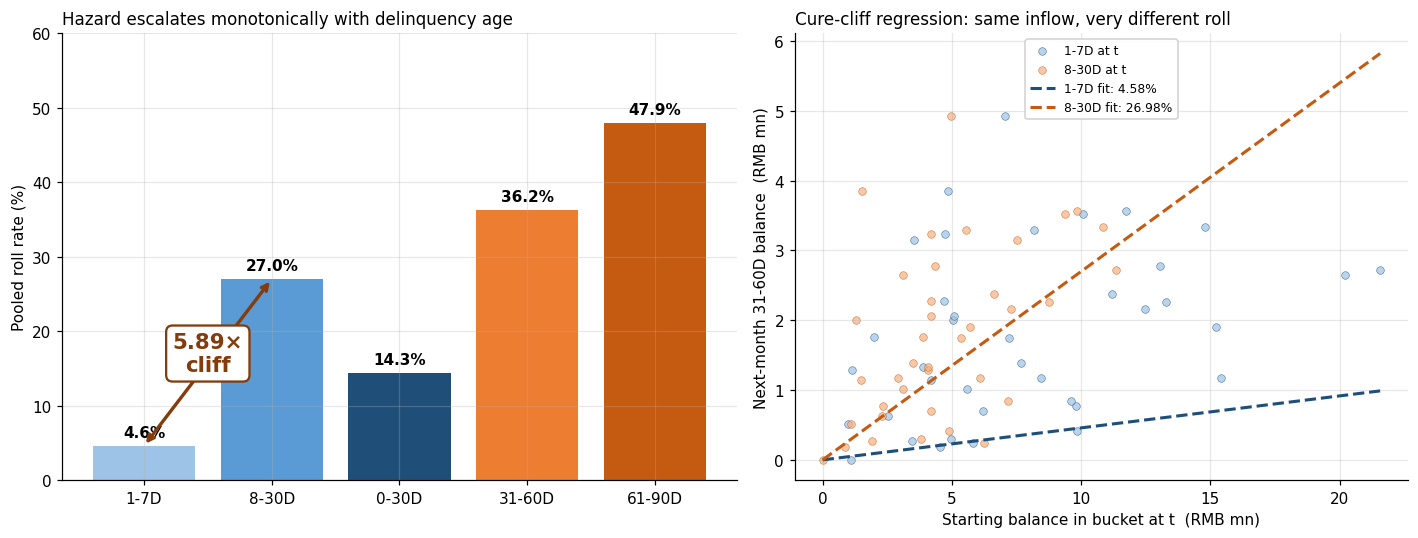

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5),
                               gridspec_kw={'width_ratios': [1.1, 1]})

stages = list(POOLED.index)
rates  = POOLED.values
bar_colors = [STAGE_COLOR[s] for s in stages]

bars = ax1.bar(stages, rates, color=bar_colors)
for b, r in zip(bars, rates):
    ax1.text(b.get_x() + b.get_width()/2, r + 1.2, f'{r:.1f}%',
             ha='center', fontsize=10, fontweight='bold')
ax1.set_ylabel('Pooled roll rate (%)'); ax1.set_ylim(0, 60)
ax1.set_title('Hazard escalates monotonically with delinquency age',
              loc='left', fontsize=11)

ax1.annotate('', xy=(1, 26.98), xytext=(0, 4.58),
             arrowprops=dict(arrowstyle='<->', color=P['deep_orange'], lw=2.2))
ax1.text(0.5, 17, '5.89×\ncliff', ha='center', va='center',
         fontsize=14, fontweight='bold', color=P['deep_orange'],
         bbox=dict(boxstyle='round,pad=0.3', fc='white',
                   ec=P['deep_orange'], lw=1.5))

# right: scatter + fitted lines
d1_7  = df['overdue 1-7D'].iloc[:-1]
d8_30 = df['overdue 8-30D'].iloc[:-1]
y     = df_buckets['overdue 31-60D'].shift(-1).iloc[:-1]

ax2.scatter(d1_7 / 1e6, y / 1e6, s=25, alpha=0.7,
            color=P['light_blue'], edgecolor=P['steel_blue'], lw=0.4, label='1-7D at t')
ax2.scatter(d8_30 / 1e6, y / 1e6, s=25, alpha=0.7,
            color=P['light_orange'], edgecolor=P['dark_orange'], lw=0.4, label='8-30D at t')

xs = np.linspace(0, max(d1_7.max(), d8_30.max()) / 1e6, 100)
ax2.plot(xs, EARLY_COEF * xs, '--', color=P['steel_blue'], lw=2,
         label=f'1-7D fit: {EARLY_COEF:.2%}')
ax2.plot(xs, LATE_COEF  * xs, '--', color=P['dark_orange'], lw=2,
         label=f'8-30D fit: {LATE_COEF:.2%}')

ax2.set_xlabel('Starting balance in bucket at t  (RMB mn)')
ax2.set_ylabel('Next-month 31-60D balance  (RMB mn)')
ax2.set_title('Cure-cliff regression: same inflow, very different roll',
              loc='left', fontsize=11)
ax2.legend(fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig('fig2_cure_cliff.png', bbox_inches='tight'); plt.show()

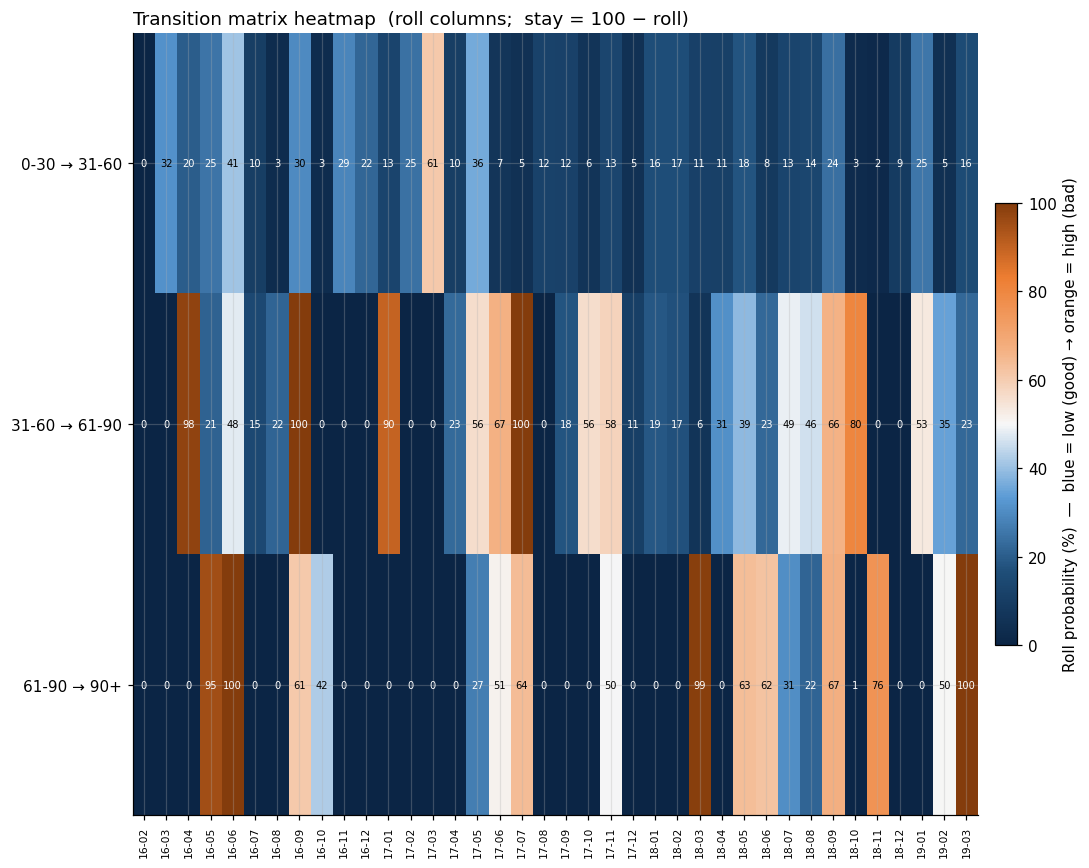

In [48]:
fig, ax = plt.subplots(figsize=(10, 8))
cols   = ['0-30D→31-60D', '31-60D→61-90D', '61-90D→90D+']
labels = ['0-30 → 31-60', '31-60 → 61-90', '61-90 → 90+']
heat   = transition_matrix[cols].T.values

im = ax.imshow(heat, aspect='auto', cmap=blue_orange, vmin=0, vmax=100)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(labels)
ax.set_xticks(range(len(transition_matrix)))
ax.set_xticklabels(transition_matrix.index.strftime('%y-%m'), rotation=90, fontsize=7)

# pick text colour from background luminance
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat[i, j]
        if np.isnan(v): continue
        r, g, b, _ = blue_orange(v / 100.0)
        lum = 0.2126*r + 0.7152*g + 0.0722*b
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=6.5,
                color='white' if lum < 0.5 else 'black')

cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label('Roll probability (%)  —  blue = low (good) → orange = high (bad)')
ax.set_title('Transition matrix heatmap  (roll columns;  stay = 100 − roll)',
             loc='left')
plt.tight_layout()
plt.savefig('fig3_transition_heatmap.png', bbox_inches='tight'); plt.show()

ValueError: The number of FixedLocator locations (24), usually from a call to set_ticks, does not match the number of labels (12).

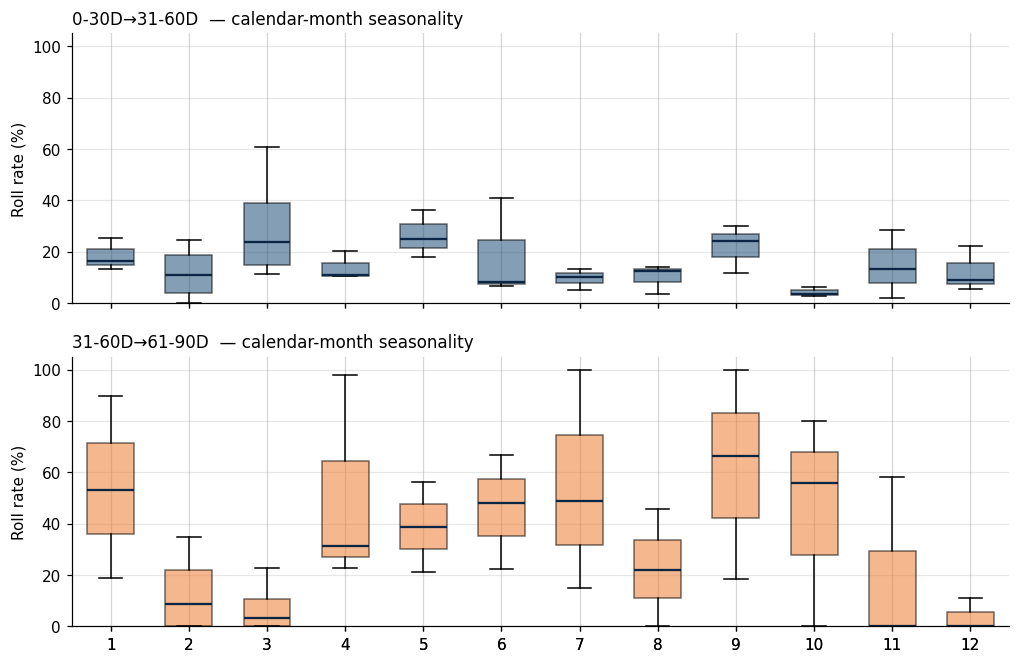

In [50]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

for col, ax, c in [
    ('0-30D→31-60D',  ax1, P['steel_blue']),
    ('31-60D→61-90D', ax2, P['orange']),
]:
    data = [roll_rates.loc[roll_rates.index.month == m, col].dropna().values
            for m in range(1, 13)]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=True,
                    medianprops=dict(color=P['navy'], lw=1.5),
                    flierprops=dict(marker='o', ms=3, alpha=0.4,
                                    markerfacecolor=c, markeredgecolor=c))
    for patch in bp['boxes']:
        patch.set_facecolor(c); patch.set_alpha(0.55)
    ax.set_ylabel('Roll rate (%)'); ax.set_ylim(0, 105)
    ax.set_title(f'{col}  — calendar-month seasonality', loc='left', fontsize=11)

ax2.set_xticklabels(months)
plt.tight_layout()
plt.savefig('fig4_seasonality.png', bbox_inches='tight'); plt.show()

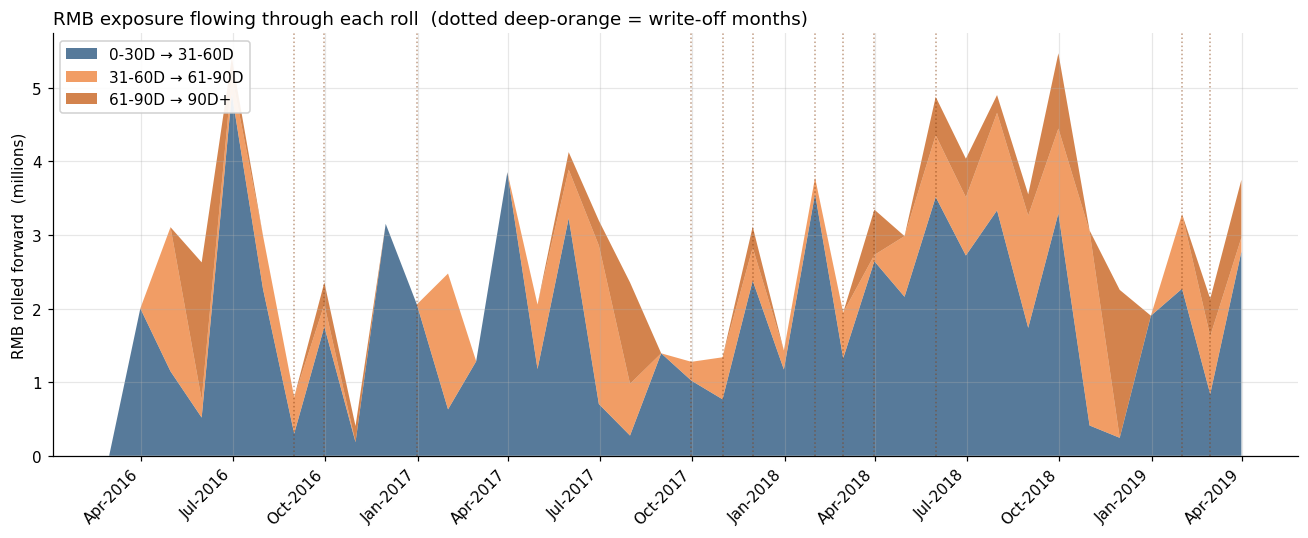

In [58]:
fig, ax = plt.subplots(figsize=(12, 5))
trans      = transition_matrix_dollars
roll_cols  = ['0-30D→31-60D', '31-60D→61-90D', '61-90D→90D+']
stack_cols = [ROLL_COLOR[c] for c in roll_cols]

ax.stackplot(trans.index,
             [trans[c] / 1e6 for c in roll_cols],
             labels=[c.replace('→', ' → ') for c in roll_cols],
             colors=stack_cols, alpha=0.75)

for wm in writeoff_months:
    ax.axvline(wm, color=P['deep_orange'], ls=':', alpha=0.5, lw=1)
    

ax.set_ylabel('RMB rolled forward  (millions)')
ax.set_title('RMB exposure flowing through each roll  '
             '(dotted deep-orange = write-off months)', loc='left')
ax.legend(loc='upper left', framealpha=0.9)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,4,7,10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig('fig5_rmb_exposure.png', bbox_inches='tight'); plt.show()

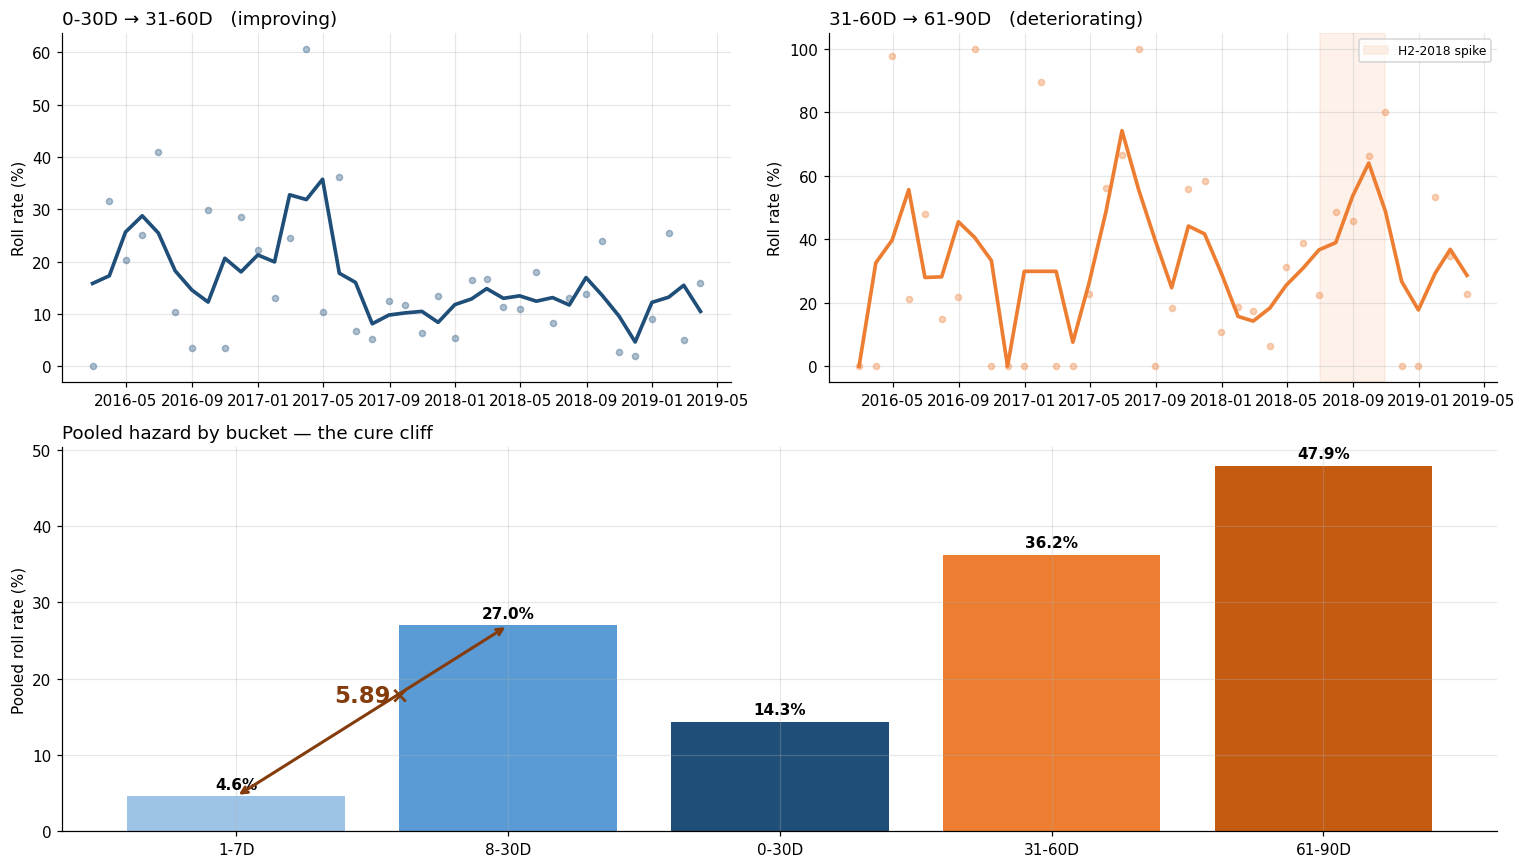

In [54]:
fig = plt.figure(figsize=(14, 8))
gs  = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])

# top-left: early-stage roll (blue, improving)
ax = fig.add_subplot(gs[0, 0])
s = roll_rates['0-30D→31-60D']
ax.plot(s.index, s.values, 'o', color=P['steel_blue'], alpha=0.35, ms=4)
ax.plot(s.index, roll3(s), '-', color=P['steel_blue'], lw=2.4)
ax.set_title('0-30D → 31-60D   (improving)', loc='left')
ax.set_ylabel('Roll rate (%)')

# top-right: mid-stage roll (orange, deteriorating)
ax = fig.add_subplot(gs[0, 1])
s = roll_rates['31-60D→61-90D']
ax.plot(s.index, s.values, 'o', color=P['orange'], alpha=0.35, ms=4)
ax.plot(s.index, roll3(s), '-', color=P['orange'], lw=2.4)
ax.axvspan(pd.Timestamp('2018-07-01'), pd.Timestamp('2018-10-31'),
           color=P['orange'], alpha=0.10, label='H2-2018 spike')
ax.set_title('31-60D → 61-90D   (deteriorating)', loc='left')
ax.set_ylabel('Roll rate (%)'); ax.legend(loc='upper right', fontsize=8)

# bottom: cure cliff
ax = fig.add_subplot(gs[1, :])
ax.bar(stages, rates, color=[STAGE_COLOR[s] for s in stages])
for i, r in enumerate(rates):
    ax.text(i, r + 1, f'{r:.1f}%', ha='center', fontweight='bold')
ax.annotate('', xy=(1, 26.98), xytext=(0, 4.58),
            arrowprops=dict(arrowstyle='<->', color=P['deep_orange'], lw=2))
ax.text(0.5, 17, '5.89×', ha='center', fontsize=15,
        fontweight='bold', color=P['deep_orange'])
ax.set_title('Pooled hazard by bucket — the cure cliff', loc='left')
ax.set_ylabel('Pooled roll rate (%)')

plt.tight_layout()
plt.savefig('fig6_exec_dashboard.png', bbox_inches='tight'); plt.show()

In [ ]:
# Roll Rate_b to b+1, t = (Overdue Balance_b+1,t)/(Overdue Balance_b,t-1)

 

 

In [ ]:
# Cure / Resolution Rate = 1 - rolling rate

In [ ]:
# In credit risk reporting, forward transition from cohort $t$, row t represents $t \to t+1$ 